In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

DATA_DIR = Path("../data/raw")

print("Libraries imported successfully!")
print("Dataset directory:", DATA_DIR.resolve())

Libraries imported successfully!
Dataset directory: C:\Users\hp\personal\HireMatch\hirematch-backend\data\raw


In [2]:
cv_df = pd.read_csv(DATA_DIR / "cv.csv")
job_df = pd.read_csv(DATA_DIR / "job.csv")
matches_df = pd.read_csv(DATA_DIR / "matches.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [3]:
print("CV Dataset:", cv_df.shape)
print("Job Dataset:", job_df.shape)
print("Matches Dataset:", matches_df.shape)

CV Dataset: (9544, 11)
Job Dataset: (1167, 10)
Matches Dataset: (122560, 13)


In [5]:
display(cv_df.head(3))
display(job_df.head(3))
display(matches_df.head(5))

,candidate_id,source_row,target_position,resume_text,clean_skills,clean_skills_json,education_text,experience_text,years_experience,inferred_category,embedding
0,cand_00000,0,Senior Software Engineer,Target position: Senior Software Engineer Objective: Big data analytics working and database war...,"[""big data"", ""hadoop"", ""hive"", ""python"", ""mapreduce"", ""spark"", ""java"", ""machine learning"", ""clou...","[""big data"", ""hadoop"", ""hive"", ""python"", ""mapreduce"", ""spark"", ""java"", ""machine learning"", ""clou...","['B.Tech'] ['Electronics'] ['The Amity School of Engineering & Technology (ASET), Noida'] B.Sc i...",At least 1 year ['Big Data Analyst'] Technical Support\nTroubleshooting\nCollaboration\nDocument...,1.0,INFORMATION-TECHNOLOGY,"[0.06282798945903778, 0.03344276547431946, -0.052133239805698395, -0.043887585401535034, 0.04524..."
1,cand_00001,1,Machine Learning (ML) Engineer,Target position: Machine Learning (ML) Engineer Objective: Fresher looking to join as a data ana...,"[""data analysis"", ""data analytics"", ""business analysis"", ""sas"", ""powerbi"", ""tableau"", ""data visu...","[""data analysis"", ""data analytics"", ""business analysis"", ""sas"", ""powerbi"", ""tableau"", ""data visu...","['B.Sc (Maths)', 'M.Sc (Science) (Statistics)'] ['Mathematics', 'Statistics'] ['Delhi University...",At least 5 year(s) ['Business Analyst'] Machine Learning Leadership\nCross-Functional Collaborat...,5.0,INFORMATION-TECHNOLOGY,"[0.038818471133708954, 0.016407284885644913, -0.04155665636062622, -0.04380759969353676, 0.03991..."
2,cand_00002,2,"Executive/ Senior Executive- Trade Marketing, Hygiene Products","Target position: Executive/ Senior Executive- Trade Marketing, Hygiene Products Objective: Skill...","[""software development"", ""machine learning"", ""deep learning"", ""risk assessment"", ""requirement ga...","[""software development"", ""machine learning"", ""deep learning"", ""risk assessment"", ""requirement ga...","['B.Tech'] ['Electronics/Telecommunication'] ['Birla Institute of Technology (BIT), Ranchi'] Mas...",At least 3 years ['Software Developer (Machine Learning Engineer)'] Trade Marketing Executive\nB...,3.0,INFORMATION-TECHNOLOGY,"[0.05784870311617851, 0.004059996455907822, -0.03691127896308899, -0.053641464561223984, 0.07488..."


,job_id,job_title,category,job_description,job_text,clean_skills,clean_skills_json,education_text,years_required,embedding
0,3651735073,Director of Finance,FINANCE,APPLY HERE\nHTTPS://WWW.INDEED.COM/JOB/DIRECTOR-FINANCE-9C0196508A30CB63\nJOB DESCRIPTIONJOB TIT...,"Job title: Director of Finance Category: FINANCE Skills: financial management, accounting, gaap ...","[""financial management"", ""accounting"", ""gaap principles"", ""budgeting"", ""forecasting"", ""financial...","[""financial management"", ""accounting"", ""gaap principles"", ""budgeting"", ""forecasting"", ""financial...",APPLY HERE\nHTTPS://WWW.INDEED.COM/JOB/DIRECTOR-FINANCE-9C0196508A30CB63\nJOB DESCRIPTIONJOB TIT...,30.0,"[-0.006719283293932676, 0.1176915317773819, -0.004483179654926062, 0.042868949472904205, 0.03256..."
1,3715891138,Human Resources Manager,HR,HUMAN RESOURCES MANAGER POSITION SUMMARYTHE IDEAL CANDIDATE WILL PERFORM ROUTINE TASKS REQUIRED...,"Job title: Human Resources Manager Category: HR Skills: recruiting, talent management, complianc...","[""recruiting"", ""talent management"", ""compliance"", ""employee engagement programs"", ""conflict reso...","[""recruiting"", ""talent management"", ""compliance"", ""employee engagement programs"", ""conflict reso...",HUMAN RESOURCES MANAGER POSITION SUMMARYTHE IDEAL CANDIDATE WILL PERFORM ROUTINE TASKS REQUIRED...,9.0,"[0.07242906838655472, -0.04977822303771973, 0.000916390388738364, -0.03447864577174187, 0.007196..."
2,3782812525,Salesperson,SALES,THE TERRA FORZA GOLF TEAM IS GROWING! TERRITORY IS TO BE DETERMINED. \nPOSITION SUMMARY\nRESPONS...,"Job title: Salesperson Category: SALES Skills: sales, customer relationship management, technica...","[""sales"", ""customer relationship management"", ""technical skills"", ""presentation skills"", ""mercha...","[""sales"", ""customer relationship management"", ""technical skills"", ""presentation skills"", ""mercha...",THE TERRA FORZA GOLF TEAM IS GROWING! TERRITORY IS TO BE DETERMINED. \nPOSITION SUMMARY\nRESPONS...,3.0,"[0.05193764343857765, -0.01702122576534748, -0.00534691009670496, 0.026864664629101753, 0.030328..."


,candidate_id,job_id,final_score,raw_score,label_strength,semantic_score,skill_score,position_score,category_score,experience_score,education_score,candidate_rank,candidate_rank_pct
0,cand_00000,3906246896,0.635354,0.479077,medium_positive,0.867852,0.215161,0.621538,0.0,0.250,1.0,1,1.000000
1,cand_00000,3902931012,0.599043,0.437020,medium_positive,0.775035,0.000000,0.341304,1.0,0.500,1.0,2,0.977099
2,cand_00000,3905214623,0.560359,0.404657,weak_positive,0.766395,0.054937,0.212903,1.0,0.025,1.0,3,0.923664
3,cand_00000,3889743825,0.540995,0.393352,weak_positive,0.821683,0.000000,0.189655,1.0,0.500,0.5,4,0.885496
4,cand_00000,3902357305,0.538510,0.393074,weak_positive,0.764884,0.046768,0.177419,1.0,0.500,0.5,5,0.877863


In [4]:
print("========== CV DATASET ==========")
print(cv_df.columns.tolist())

print("\n========== JOB DATASET ==========")
print(job_df.columns.tolist())

print("\n========== MATCHES DATASET ==========")
print(matches_df.columns.tolist())

========== CV DATASET ==========
['candidate_id', 'source_row', 'target_position', 'resume_text', 'clean_skills', 'clean_skills_json', 'education_text', 'experience_text', 'years_experience', 'inferred_category', 'embedding']

========== JOB DATASET ==========
['job_id', 'job_title', 'category', 'job_description', 'job_text', 'clean_skills', 'clean_skills_json', 'education_text', 'years_required', 'embedding']

========== MATCHES DATASET ==========
['candidate_id', 'job_id', 'final_score', 'raw_score', 'label_strength', 'semantic_score', 'skill_score', 'position_score', 'category_score', 'experience_score', 'education_score', 'candidate_rank', 'candidate_rank_pct']


In [6]:
datasets = {
    "CV": cv_df,
    "Job": job_df,
    "Matches": matches_df
}

for name, df in datasets.items():
    print(f"\n========== {name} DATASET ==========")

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:")
    print(df.duplicated().sum())


========== CV DATASET ==========

Data types:
candidate_id             str
source_row             int64
target_position          str
resume_text              str
clean_skills             str
clean_skills_json        str
education_text           str
experience_text          str
years_experience     float64
inferred_category        str
embedding                str
dtype: object

Missing values:
candidate_id         0
source_row           0
target_position      0
resume_text          0
clean_skills         0
clean_skills_json    0
education_text       0
experience_text      0
years_experience     0
inferred_category    0
embedding            0
dtype: int64

Duplicate rows:
0

========== Job DATASET ==========

Data types:
job_id                 int64
job_title                str
category                 str
job_description          str
job_text                 str
clean_skills             str
clean_skills_json        str
education_text           str
years_required       float64
embedding

In [7]:
print("CV sample:")
display(cv_df.head(2))

print("Job sample:")
display(job_df.head(2))

print("Matches sample:")
display(matches_df.head(5))

CV sample:


,candidate_id,source_row,target_position,resume_text,clean_skills,clean_skills_json,education_text,experience_text,years_experience,inferred_category,embedding
0,cand_00000,0,Senior Software Engineer,Target position: Senior Software Engineer Objective: Big data analytics working and database war...,"[""big data"", ""hadoop"", ""hive"", ""python"", ""mapreduce"", ""spark"", ""java"", ""machine learning"", ""clou...","[""big data"", ""hadoop"", ""hive"", ""python"", ""mapreduce"", ""spark"", ""java"", ""machine learning"", ""clou...","['B.Tech'] ['Electronics'] ['The Amity School of Engineering & Technology (ASET), Noida'] B.Sc i...",At least 1 year ['Big Data Analyst'] Technical Support\nTroubleshooting\nCollaboration\nDocument...,1.0,INFORMATION-TECHNOLOGY,"[0.06282798945903778, 0.03344276547431946, -0.052133239805698395, -0.043887585401535034, 0.04524..."
1,cand_00001,1,Machine Learning (ML) Engineer,Target position: Machine Learning (ML) Engineer Objective: Fresher looking to join as a data ana...,"[""data analysis"", ""data analytics"", ""business analysis"", ""sas"", ""powerbi"", ""tableau"", ""data visu...","[""data analysis"", ""data analytics"", ""business analysis"", ""sas"", ""powerbi"", ""tableau"", ""data visu...","['B.Sc (Maths)', 'M.Sc (Science) (Statistics)'] ['Mathematics', 'Statistics'] ['Delhi University...",At least 5 year(s) ['Business Analyst'] Machine Learning Leadership\nCross-Functional Collaborat...,5.0,INFORMATION-TECHNOLOGY,"[0.038818471133708954, 0.016407284885644913, -0.04155665636062622, -0.04380759969353676, 0.03991..."


Job sample:


,job_id,job_title,category,job_description,job_text,clean_skills,clean_skills_json,education_text,years_required,embedding
0,3651735073,Director of Finance,FINANCE,APPLY HERE\nHTTPS://WWW.INDEED.COM/JOB/DIRECTOR-FINANCE-9C0196508A30CB63\nJOB DESCRIPTIONJOB TIT...,"Job title: Director of Finance Category: FINANCE Skills: financial management, accounting, gaap ...","[""financial management"", ""accounting"", ""gaap principles"", ""budgeting"", ""forecasting"", ""financial...","[""financial management"", ""accounting"", ""gaap principles"", ""budgeting"", ""forecasting"", ""financial...",APPLY HERE\nHTTPS://WWW.INDEED.COM/JOB/DIRECTOR-FINANCE-9C0196508A30CB63\nJOB DESCRIPTIONJOB TIT...,30.0,"[-0.006719283293932676, 0.1176915317773819, -0.004483179654926062, 0.042868949472904205, 0.03256..."
1,3715891138,Human Resources Manager,HR,HUMAN RESOURCES MANAGER POSITION SUMMARYTHE IDEAL CANDIDATE WILL PERFORM ROUTINE TASKS REQUIRED...,"Job title: Human Resources Manager Category: HR Skills: recruiting, talent management, complianc...","[""recruiting"", ""talent management"", ""compliance"", ""employee engagement programs"", ""conflict reso...","[""recruiting"", ""talent management"", ""compliance"", ""employee engagement programs"", ""conflict reso...",HUMAN RESOURCES MANAGER POSITION SUMMARYTHE IDEAL CANDIDATE WILL PERFORM ROUTINE TASKS REQUIRED...,9.0,"[0.07242906838655472, -0.04977822303771973, 0.000916390388738364, -0.03447864577174187, 0.007196..."


Matches sample:


,candidate_id,job_id,final_score,raw_score,label_strength,semantic_score,skill_score,position_score,category_score,experience_score,education_score,candidate_rank,candidate_rank_pct
0,cand_00000,3906246896,0.635354,0.479077,medium_positive,0.867852,0.215161,0.621538,0.0,0.250,1.0,1,1.000000
1,cand_00000,3902931012,0.599043,0.437020,medium_positive,0.775035,0.000000,0.341304,1.0,0.500,1.0,2,0.977099
2,cand_00000,3905214623,0.560359,0.404657,weak_positive,0.766395,0.054937,0.212903,1.0,0.025,1.0,3,0.923664
3,cand_00000,3889743825,0.540995,0.393352,weak_positive,0.821683,0.000000,0.189655,1.0,0.500,0.5,4,0.885496
4,cand_00000,3902357305,0.538510,0.393074,weak_positive,0.764884,0.046768,0.177419,1.0,0.500,0.5,5,0.877863


In [8]:
print("========== DATASET SUMMARY ==========")

for name, df in datasets.items():
    print(f"\n{name}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("Missing cells:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())

========== DATASET SUMMARY ==========

CV
Rows: 9544
Columns: 11
Missing cells: 0
Duplicate rows: 0

Job
Rows: 1167
Columns: 10
Missing cells: 0
Duplicate rows: 0

Matches
Rows: 122560
Columns: 13
Missing cells: 0
Duplicate rows: 0


In [9]:
print("========== UNIQUE ID COUNTS ==========")

print("CV rows:", len(cv_df))
print("Unique candidates:", cv_df["candidate_id"].nunique())

print("\nJob rows:", len(job_df))
print("Unique jobs:", job_df["job_id"].nunique())

print("\nMatch rows:", len(matches_df))
print("Unique candidates in matches:", matches_df["candidate_id"].nunique())
print("Unique jobs in matches:", matches_df["job_id"].nunique())

print(
    "\nDuplicate candidate-job pairs:",
    matches_df.duplicated(subset=["candidate_id", "job_id"]).sum()
)

========== UNIQUE ID COUNTS ==========
CV rows: 9544
Unique candidates: 9544

Job rows: 1167
Unique jobs: 1167

Match rows: 122560
Unique candidates in matches: 9532
Unique jobs in matches: 1164

Duplicate candidate-job pairs: 0


In [10]:
cv_ids = set(cv_df["candidate_id"])
job_ids = set(job_df["job_id"])

matched_candidate_ids = set(matches_df["candidate_id"])
matched_job_ids = set(matches_df["job_id"])

print("========== RELATIONSHIP VALIDATION ==========")

print(
    "Matches with unknown candidates:",
    len(matched_candidate_ids - cv_ids)
)

print(
    "Matches with unknown jobs:",
    len(matched_job_ids - job_ids)
)

print(
    "CV candidates without matches:",
    len(cv_ids - matched_candidate_ids)
)

print(
    "Jobs without matches:",
    len(job_ids - matched_job_ids)
)

========== RELATIONSHIP VALIDATION ==========
Matches with unknown candidates: 0
Matches with unknown jobs: 0
CV candidates without matches: 12
Jobs without matches: 3


In [11]:
score_columns = [
    "final_score",
    "raw_score",
    "semantic_score",
    "skill_score",
    "position_score",
    "category_score",
    "experience_score",
    "education_score",
    "candidate_rank_pct"
]

display(matches_df[score_columns].describe().round(3))

,final_score,raw_score,semantic_score,skill_score,position_score,category_score,experience_score,education_score,candidate_rank_pct
count,122560.000,122560.000,122560.000,122560.000,122560.000,122560.000,122560.000,122560.000,122560.000
mean,0.586,0.436,0.781,0.058,0.266,0.885,0.676,0.897,0.935
std,0.036,0.037,0.042,0.076,0.182,0.319,0.350,0.210,0.054
min,0.430,0.306,0.581,0.000,0.023,0.000,0.000,0.300,0.383
25%,0.564,0.414,0.755,0.000,0.142,1.000,0.500,1.000,0.906
50%,0.587,0.435,0.785,0.036,0.194,1.000,0.800,1.000,0.944
75%,0.608,0.456,0.810,0.089,0.345,1.000,1.000,1.000,0.974
max,0.756,0.652,0.918,0.617,1.000,1.000,1.000,1.000,1.000


In [12]:
print("========== LABEL DISTRIBUTION ==========")

print(matches_df["label_strength"].value_counts(dropna=False))

print("\nPercentage distribution:")

print(
    matches_df["label_strength"]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

========== LABEL DISTRIBUTION ==========
label_strength
medium_positive    70636
weak_positive      51150
strong_positive      774
Name: count, dtype: int64

Percentage distribution:
label_strength
medium_positive    57.63
weak_positive      41.73
strong_positive     0.63
Name: proportion, dtype: float64


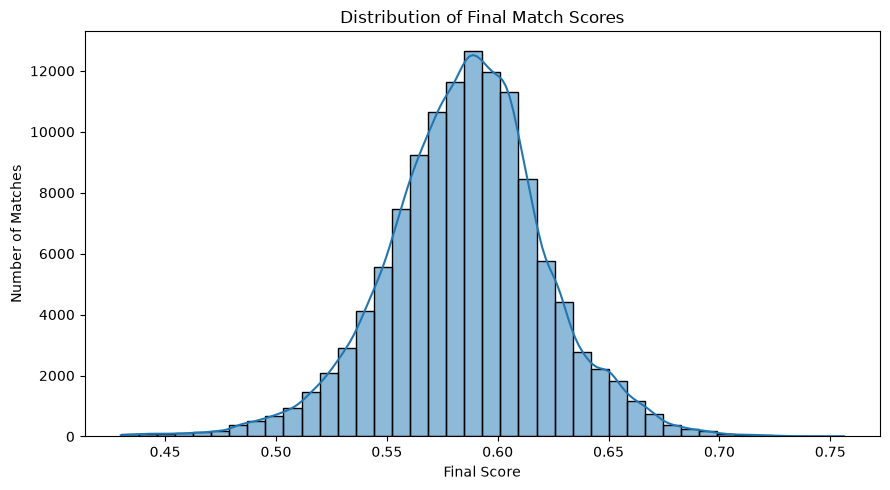

In [13]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=matches_df,
    x="final_score",
    bins=40,
    kde=True
)

plt.title("Distribution of Final Match Scores")
plt.xlabel("Final Score")
plt.ylabel("Number of Matches")

plt.tight_layout()
plt.show()

In [14]:
print("========== CV EMBEDDING ==========")

cv_embedding = cv_df["embedding"].iloc[0]

print("Python type:", type(cv_embedding))
print("Sample:", str(cv_embedding)[:200])
print("String length:", len(str(cv_embedding)))

print("\n========== JOB EMBEDDING ==========")

job_embedding = job_df["embedding"].iloc[0]

print("Python type:", type(job_embedding))
print("Sample:", str(job_embedding)[:200])
print("String length:", len(str(job_embedding)))

========== CV EMBEDDING ==========
Python type: <class 'str'>
Sample: [0.06282798945903778, 0.03344276547431946, -0.052133239805698395, -0.043887585401535034, 0.04524204134941101, 0.016655540093779564, -0.05059404671192169, -0.022055206820368767, 0.03531971573829651, -0
String length: 16992

========== JOB EMBEDDING ==========
Python type: <class 'str'>
Sample: [-0.006719283293932676, 0.1176915317773819, -0.004483179654926062, 0.042868949472904205, 0.032560624182224274, 0.046416062861680984, -0.047530777752399445, -0.009987003169953823, -0.03191830590367317,
String length: 17036


In [15]:
print("Resume text lengths:")
display(cv_df["resume_text"].str.len().describe())

print("\nJob description lengths:")
display(job_df["job_description"].str.len().describe())

Resume text lengths:


count    9544.000000
mean     1397.698973
std       449.750230
min       493.000000
25%      1051.000000
50%      1301.000000
75%      1682.000000
max      3000.000000
Name: resume_text, dtype: float64


Job description lengths:


count     1167.000000
mean      3768.040274
std       2102.977470
min        167.000000
25%       2123.500000
50%       3445.000000
75%       4932.500000
max      13639.000000
Name: job_description, dtype: float64

In [16]:
print("Average final score by label:")

display(
    matches_df.groupby("label_strength")["final_score"]
    .agg(["count", "mean", "min", "max"])
    .round(3)
)

Average final score by label:


,count,mean,min,max
label_strength,,,,
medium_positive,70636,0.608,0.58,0.680
strong_positive,774,0.696,0.68,0.756
weak_positive,51150,0.553,0.43,0.580


In [17]:
display(
    matches_df.groupby("label_strength")[
        ["raw_score", "semantic_score", "skill_score",
         "position_score", "category_score",
         "experience_score", "education_score"]
    ].mean().round(3)
)

,raw_score,semantic_score,skill_score,position_score,category_score,experience_score,education_score
label_strength,,,,,,,
medium_positive,0.456,0.790,0.067,0.291,0.924,0.770,0.919
strong_positive,0.568,0.802,0.272,0.426,0.953,0.871,0.959
weak_positive,0.406,0.769,0.042,0.228,0.829,0.544,0.866


In [18]:
import json
import numpy as np

cv_vector = np.array(
    json.loads(cv_df["embedding"].iloc[0]),
    dtype=np.float32
)

job_vector = np.array(
    json.loads(job_df["embedding"].iloc[0]),
    dtype=np.float32
)

print("CV embedding shape:", cv_vector.shape)
print("Job embedding shape:", job_vector.shape)

print("CV embedding norm:", np.linalg.norm(cv_vector))
print("Job embedding norm:", np.linalg.norm(job_vector))

CV embedding shape: (768,)
Job embedding shape: (768,)
CV embedding norm: 1.0
Job embedding norm: 1.0000001


In [19]:
cv_dimensions = cv_df["embedding"].apply(
    lambda x: len(json.loads(x))
)

job_dimensions = job_df["embedding"].apply(
    lambda x: len(json.loads(x))
)

print("CV embedding dimensions:")
print(cv_dimensions.value_counts())

print("\nJob embedding dimensions:")
print(job_dimensions.value_counts())

CV embedding dimensions:
embedding
768    9544
Name: count, dtype: int64

Job embedding dimensions:
embedding
768    1167
Name: count, dtype: int64


In [20]:
score_columns = [
    "raw_score",
    "semantic_score",
    "skill_score",
    "position_score",
    "category_score",
    "experience_score",
    "education_score"
]

correlations = matches_df[
    score_columns + ["final_score"]
].corr()

display(
    correlations[["final_score"]]
    .sort_values("final_score", ascending=False)
)

,final_score
final_score,1.000000
raw_score,0.913803
experience_score,0.370245
semantic_score,0.283934
skill_score,0.273132
position_score,0.271888
category_score,0.186092
education_score,0.131749


In [21]:
display(
    matches_df.groupby("label_strength")["final_score"]
    .agg(["min", "max"])
)

,min,max
label_strength,,
medium_positive,0.580000,0.679999
strong_positive,0.680003,0.756099
weak_positive,0.430009,0.580000
